# Evaluación Parcial 3 · Aprendizaje supervisado
## Horse Colic: regresión y clasificación
**Asignatura:** TLY1101 — Machine Learning · Duoc UC  
**Estudiante identificado en EP1:** Ariel Aravena Muñoz  
**Fecha de preparación:** 28 de octubre de 2026  
**Estado:** borrador técnico asistido por IA, con experimentos reproducibles. Requiere revisión y validación del estudiante antes de entregar. Confirmar integrantes según las instrucciones del docente.

### Propósito y continuidad con EP1
En este informe continúo el estudio de Horse Colic iniciado en la primera entrega. Comparo modelos para estimar el pulso y para clasificar la presencia retrospectiva de una lesión quirúrgica. El propósito organizacional propuesto es explorar información útil para la evaluación de casos veterinarios y para la calidad de registros clínicos. No se demuestra utilidad clínica ni se recomienda usar estos modelos para decidir tratamientos.

Conservo el mismo archivo de 300 registros estudiado en EP1. Reconstruyo el preprocesamiento desde esos datos para ajustar sus parámetros únicamente con entrenamiento. El CSV de EP1 se había imputado y escalado antes de dividir los datos, por lo que no permite una evaluación independiente. Esta modificación mantiene la continuidad del caso y corrige la fuga de información.

### Guía de cobertura de la rúbrica
| Indicador | Evidencia en este notebook |
|---|---|
| IE1 | Ridge y Random Forest de regresión, ambos con búsqueda de hiperparámetros |
| IE2 | MSE, RMSE y R², validación cruzada y prueba |
| IE3 | Regresión logística, árbol y Random Forest de clasificación, todos optimizados |
| IE4 | Conteo de clases; comparación explícita con y sin ponderación |
| IE5 | Matrices de confusión, accuracy, precisión, recall, F1 y ROC/AUC |
| IE6 | Comparación cuantitativa, discusión y criterio de selección previo |
| IE7 | Tablas de validación cruzada, dispersión, configuración y prueba reservada |
| IE8 | Notebook estructurado, código, Markdown, conclusiones y referencias |

Esta tabla localiza evidencia; no constituye una calificación ni una certificación de cumplimiento docente.

## 1. Objetivos, hipótesis y protocolo de evaluación

**Regresión (objetivo propuesto):** estimar `pulse`, medido en pulsaciones por minuto, a partir de otras observaciones. Sirve como ejercicio de reconstrucción de una medición ausente y exploración de asociaciones. Debo justificar con el docente su pertinencia para el caso: medir directamente el pulso puede ser más simple que estimarlo. No imputo la etiqueta ni la recorto; evalúo solo registros con pulso observado. No asumo que el desempeño en esos registros represente a los casos originalmente sin pulso.

**Clasificación:** predecir `surgical_lesion` (1 = sí, 0 = no) usando datos del examen. Es una etiqueta retrospectiva, no una orden de operar. Priorizo F1 de la clase positiva en validación como compromiso entre precisión y recall; también analizo falsos negativos por su posible relevancia. No asigno costos clínicos sin evidencia.

**Protocolo fijado antes de evaluar:** separación aproximada 80/20 mediante `GroupShuffleSplit`, semilla 42 y sin buscar una partición con resultados favorables. Mantengo cada `hospital_number` en una sola partición para reducir el riesgo de evaluar casos repetidos del mismo caballo. El diccionario indica que el identificador puede repetirse al tratar nuevamente al caballo; no permite garantizar identidad biológica perfecta. Uso 5 folds agrupados dentro del entrenamiento; en clasificación, estratificación por grupos cuando sea posible. Selecciono familias e hiperparámetros por validación cruzada: menor RMSE en regresión y mayor F1 positivo en clasificación. Prueba se usa una sola vez para el reporte final; no cambio la selección según esos resultados.

Los hiperparámetros ganadores y la puntuación de búsqueda usan los mismos folds, por lo que la puntuación de validación puede ser optimista. La prueba reservada aporta una comprobación independiente; no se ejecuta validación anidada ni se afirma significancia estadística.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform, time, zipfile, io, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, StratifiedGroupKFold, GridSearchCV
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, make_scorer)

SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_columns', 30)
pd.set_option('display.precision', 4)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True})
BASE = Path.cwd()
if BASE.name == 'notebooks': BASE = BASE.parent
RESULTS = BASE / 'resultados'
RESULTS.mkdir(exist_ok=True)
versions = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'scikit-learn': sklearn.__version__}
display(pd.Series(versions, name='versión'))

python          3.12.3
numpy            2.0.0
pandas           2.2.3
scikit-learn     1.5.0
Name: versión, dtype: object

## 2. Datos, trazabilidad y correcciones de EP1

Fuente: McLeish, M. y Cecile, M. (1989), *Horse Colic*, UCI, DOI [10.24432/C58W23](https://doi.org/10.24432/C58W23), licencia CC BY 4.0. UCI distribuye 300 casos en `horse-colic.data` y otros 68 en `horse-colic.test`. Aquí utilizo únicamente los 300 originales de EP1; los 68 externos no se evalúan.

La descarga automática solo ocurre si falta el archivo local. Compruebo la huella de los bytes para mantener los datos de esta ejecución. El notebook y `horse-colic.data` deben estar en la misma carpeta al ejecutarse sin conexión.

In [2]:
DATA = BASE / 'data' / 'horse-colic.data'
EXPECTED_SHA256 = '270db486c78796143ffa84b4808118b3d4b96d1bd0f70bf22b3bb0bfca21e547'
if not DATA.exists():
    url = 'https://archive.ics.uci.edu/static/public/47/horse+colic.zip'
    with urllib.request.urlopen(url, timeout=60) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    DATA.write_bytes(archive.read('horse-colic.data'))
data_sha256 = hashlib.sha256(DATA.read_bytes()).hexdigest()
assert data_sha256 == EXPECTED_SHA256, 'Los datos no coinciden con la versión documentada.'
columns = ['surgery','age','hospital_number','rectal_temperature','pulse',
 'respiratory_rate','temp_extremities','peripheral_pulse','mucous_membranes',
 'capillary_refill_time','pain','peristalsis','abdominal_distension',
 'nasogastric_tube','nasogastric_reflux','nasogastric_reflux_ph','rectal_exam_feces',
 'abdomen','packed_cell_volume','total_protein','abdomcentesis_appearance',
 'abdomcentesis_total_protein','outcome','surgical_lesion','lesion_1','lesion_2',
 'lesion_3','cp_data']
raw = pd.read_csv(DATA, sep=r'\s+', header=None, names=columns, na_values='?')
assert raw.shape == (300, 28)
assert raw['hospital_number'].notna().all()
assert set(raw['surgical_lesion'].dropna().unique()) <= {1, 2}
print('Dimensiones:', raw.shape, '\nSHA-256:', data_sha256)
display(raw.head())
display(pd.DataFrame({'faltantes': raw.isna().sum(), '%': raw.isna().mean()*100})
        .sort_values('%', ascending=False))
print('Códigos de edad observados:', raw['age'].value_counts().to_dict())
print('IDs únicos:', raw['hospital_number'].nunique())
print('Filas con identificador repetido:', raw['hospital_number'].duplicated(keep=False).sum())

Dimensiones: (300, 28) 
SHA-256: 270db486c78796143ffa84b4808118b3d4b96d1bd0f70bf22b3bb0bfca21e547
Códigos de edad observados: {1: 276, 9: 24}
IDs únicos: 284
Filas con identificador repetido: 32


,surgery,age,hospital_number,rectal_temperature,pulse,respiratory_rate,temp_extremities,peripheral_pulse,mucous_membranes,capillary_refill_time,pain,peristalsis,abdominal_distension,nasogastric_tube,nasogastric_reflux,nasogastric_reflux_ph,rectal_exam_feces,abdomen,packed_cell_volume,total_protein,abdomcentesis_appearance,abdomcentesis_total_protein,outcome,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data
0,2.0,1,530101,38.5,66.0,28.0,3.0,3.0,NaN,2.0,5.0,4.0,4.0,NaN,NaN,NaN,3.0,5.0,45.0,8.4,NaN,NaN,2.0,2,11300,0,0,2
1,1.0,1,534817,39.2,88.0,20.0,NaN,NaN,4.0,1.0,3.0,4.0,2.0,NaN,NaN,NaN,4.0,2.0,50.0,85.0,2.0,2.0,3.0,2,2208,0,0,2
2,2.0,1,530334,38.3,40.0,24.0,1.0,1.0,3.0,1.0,3.0,3.0,1.0,NaN,NaN,NaN,1.0,1.0,33.0,6.7,NaN,NaN,1.0,2,0,0,0,1
3,1.0,9,5290409,39.1,164.0,84.0,4.0,1.0,6.0,2.0,2.0,4.0,4.0,1.0,2.0,5.0,3.0,NaN,48.0,7.2,3.0,5.3,2.0,1,2208,0,0,1
4,2.0,1,530255,37.3,104.0,35.0,NaN,NaN,6.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,74.0,7.4,NaN,NaN,2.0,2,4300,0,0,2


,faltantes,%
nasogastric_reflux_ph,247,82.3333
abdomcentesis_total_protein,198,66.0000
abdomcentesis_appearance,165,55.0000
abdomen,118,39.3333
nasogastric_reflux,106,35.3333
nasogastric_tube,104,34.6667
rectal_exam_feces,102,34.0000
peripheral_pulse,69,23.0000
rectal_temperature,60,20.0000
respiratory_rate,58,19.3333


### Decisiones de variables y tratamiento

- `age`: el diccionario describe 1 y 2, pero el archivo contiene 9. Conservo cada código observado como categoría nominal (`codigo_1`, `codigo_9`); no afirmo que 9 signifique joven ni lo convierto en faltante. Es una discrepancia pendiente de resolver con la fuente.
- `pain`: lo trato como nominal, siguiendo la advertencia del diccionario UCI de no considerarlo ordenado. Para las otras categorías también uso One-Hot: evita imponer distancias o jerarquías clínicas no validadas. Incluyo `nasogastric_reflux`, omitida accidentalmente en el ensamblado de EP1.
- Excluyo `surgery`, `outcome`, `surgical_lesion` y los códigos de lesión de los predictores: evito usar tratamiento, desenlace y diagnóstico retrospectivo como si fueran información previa. `hospital_number` solo agrupa; `cp_data` no es predictor clínico.
- Excluyo las tres mediciones con más de 40% de faltantes ya descartadas en EP1: `nasogastric_reflux_ph`, `abdomcentesis_appearance`, `abdomcentesis_total_protein`. La decisión se hereda de EP1; no se redefine inspeccionando prueba. Esa exploración histórica limita el carácter totalmente nuevo del holdout.
- Excluyo provisionalmente `total_protein`: el archivo muestra valores en escalas muy diferentes respecto al rango descrito. No dispongo de evidencia para corregir unidades por fila. No afirmo que sean errores; esta decisión conservadora limita información y debe revisarse.
- No winsorizo de manera automática: valores extremos pueden describir casos graves. La mediana para numéricas es sencilla y robusta; moda para categorías. Ambas se aprenden dentro de cada fold. `StandardScaler` se aplica después de imputar numéricas; no requiere normalidad. Los árboles no necesitan escalamiento, pero compartirlo no altera el orden de los valores.

Asumo que las variables del examen elegidas están disponibles para el momento de predicción planteado. No hay marcas de tiempo que permitan verificarlo: es una limitación explícita.

In [3]:
numeric_clf = ['rectal_temperature','pulse','respiratory_rate','packed_cell_volume']
categorical = ['age','temp_extremities','peripheral_pulse','mucous_membranes',
 'capillary_refill_time','pain','peristalsis','abdominal_distension',
 'nasogastric_tube','nasogastric_reflux','rectal_exam_feces','abdomen']
numeric_reg = [c for c in numeric_clf if c != 'pulse']
data = raw.copy()
for c in categorical:
    # Transformación determinista: no estima parámetros ni borra códigos desconocidos.
    data[c] = data[c].map(lambda v: f'codigo_{int(v)}' if pd.notna(v) else np.nan)

def preprocessor(numeric):
    return ColumnTransformer([
        ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')),
                              ('scaler', StandardScaler())]), numeric),
        ('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical)
    ], remainder='drop')

def partition(frame, features, target):
    observed = frame[target].notna()
    clean = frame.loc[observed]
    X, y = clean[features].copy(), clean[target].copy()
    groups = clean['hospital_number'].copy()
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
    train, test = next(splitter.split(X, y, groups))
    assert not set(groups.iloc[train]) & set(groups.iloc[test])
    assignment = pd.DataFrame({'fila_original': clean.index,
                              'hospital_number': groups.to_numpy(), 'particion': 'train'})
    assignment.loc[test, 'particion'] = 'test'
    return X.iloc[train], X.iloc[test], y.iloc[train], y.iloc[test], groups.iloc[train], assignment

Xr_train, Xr_test, yr_train, yr_test, gr_train, split_reg = partition(
    data, numeric_reg + categorical, 'pulse')
clf_data = data.copy()
clf_data['target'] = clf_data['surgical_lesion'].map({1: 1, 2: 0})
Xc_train, Xc_test, yc_train, yc_test, gc_train, split_clf = partition(
    clf_data, numeric_clf + categorical, 'target')
yc_train, yc_test = yc_train.astype(int), yc_test.astype(int)
assert yc_train.nunique() == yc_test.nunique() == 2
folds_reg = list(GroupKFold(n_splits=5).split(Xr_train, yr_train, gr_train))
folds_clf = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
                 .split(Xc_train, yc_train, gc_train))
for folds, groups in [(folds_reg, gr_train), (folds_clf, gc_train)]:
    for tr, va in folds:
        assert not set(groups.iloc[tr]) & set(groups.iloc[va])
for tr, va in folds_clf:
    assert yc_train.iloc[tr].nunique() == yc_train.iloc[va].nunique() == 2
print('Regresión — entrenamiento/prueba:', len(yr_train), len(yr_test),
      '| etiquetas ausentes excluidas:', raw['pulse'].isna().sum())
print('Clasificación — entrenamiento/prueba:', len(yc_train), len(yc_test))
display(pd.DataFrame([{'tarea': task, 'fold': i+1, 'train': len(tr), 'validación': len(va)}
    for task, folds in [('regresión', folds_reg), ('clasificación', folds_clf)]
    for i, (tr, va) in enumerate(folds)]))
split_reg.to_csv(RESULTS/'particiones_regresion.csv', index=False)
split_clf.to_csv(RESULTS/'particiones_clasificacion.csv', index=False)

Regresión — entrenamiento/prueba: 220 56 | etiquetas ausentes excluidas: 24
Clasificación — entrenamiento/prueba: 236 64


,tarea,fold,train,validación
0,regresión,1,176,44
1,regresión,2,176,44
2,regresión,3,176,44
3,regresión,4,176,44
4,regresión,5,176,44
5,clasificación,1,190,46
6,clasificación,2,190,46
7,clasificación,3,190,46
8,clasificación,4,188,48
9,clasificación,5,186,50


## 3. Regresión: referencias, optimización y validación (IE1, IE2)

Comparo **Ridge**, un modelo lineal regularizado, con **Random Forest**, que combina árboles y puede captar relaciones no lineales. En Ridge exploro `alpha`, la fuerza de regularización. En el bosque exploro profundidad, mínimo de observaciones por hoja y proporción de variables consideradas en cada división. Fijo 120 árboles para controlar tiempo de ejecución.

`DummyRegressor` predice la media de entrenamiento y es una referencia adicional; no cuenta como uno de los dos algoritmos exigidos. Una mejora frente a esta referencia debe observarse en validación y revisarse en prueba.

MSE promedia errores al cuadrado, RMSE devuelve el error a la unidad del pulso y R² compara contra predecir la media del conjunto evaluado. R² puede ser negativo: no debe ocultarse. Selecciono por RMSE medio de los folds. No utilizo prueba durante la búsqueda.

In [4]:
reg_candidates = {
 'Referencia media': (DummyRegressor(strategy='mean'), {}),
 'Ridge': (Ridge(), {'model__alpha': [0.1, 1.0, 10.0, 100.0]}),
 'Random Forest': (RandomForestRegressor(n_estimators=120, random_state=SEED, n_jobs=1),
   {'model__max_depth': [None, 5], 'model__min_samples_leaf': [2, 5],
    'model__max_features': [0.7, 1.0]})
}
reg_search, reg_rows = {}, []
for name, (model, params) in reg_candidates.items():
    start = time.perf_counter()
    search = GridSearchCV(Pipeline([('prep', preprocessor(numeric_reg)), ('model', model)]),
        params, cv=folds_reg,
        scoring={'rmse': 'neg_root_mean_squared_error', 'mse': 'neg_mean_squared_error', 'r2': 'r2'},
        refit='rmse', n_jobs=1, error_score='raise', return_train_score=True)
    search.fit(Xr_train, yr_train)
    reg_search[name] = search
    i = search.best_index_
    reg_rows.append({'modelo': name,
        'RMSE_CV': -search.cv_results_['mean_test_rmse'][i],
        'RMSE_CV_std': search.cv_results_['std_test_rmse'][i],
        'MSE_CV': -search.cv_results_['mean_test_mse'][i],
        'R2_CV': search.cv_results_['mean_test_r2'][i],
        'RMSE_train_CV': -search.cv_results_['mean_train_rmse'][i],
        'segundos': time.perf_counter()-start, 'parametros': search.best_params_})
    pd.DataFrame(search.cv_results_).to_csv(RESULTS/f'busqueda_reg_{name.replace(" ", "_")}.csv', index=False)
reg_cv = pd.DataFrame(reg_rows).sort_values('RMSE_CV').reset_index(drop=True)
selected_reg = reg_cv[reg_cv['modelo'] != 'Referencia media'].iloc[0]['modelo']
display(reg_cv)
print('Modelo de regresión seleccionado por validación:', selected_reg)

Modelo de regresión seleccionado por validación: Random Forest


,modelo,RMSE_CV,RMSE_CV_std,MSE_CV,R2_CV,RMSE_train_CV,segundos,parametros
0,Random Forest,18.0952,2.3809,333.1042,0.5828,12.0505,16.3051,"{'model__max_depth': 5, 'model__max_features':..."
1,Ridge,20.2508,2.4508,416.1008,0.4710,16.4825,1.2009,{'model__alpha': 10.0}
2,Referencia media,28.7958,3.5950,842.1224,-0.0574,28.6875,0.2581,{}


## 4. Clasificación: desbalance, búsqueda y métricas (IE3, IE4, IE5)

Primero cuantifico la distribución en entrenamiento. Exploro explícitamente `class_weight=None` frente a `class_weight='balanced'` para las tres familias. La ponderación balanceada aumenta el peso de clases menos frecuentes y se calcula durante el ajuste de cada fold. No modifica prueba ni inventa muestras. Evito SMOTE en esta muestra pequeña con variables codificadas, donde la interpolación requiere cuidado.

La comparación con y sin ponderación se muestra aunque el mejor resultado no la use: aplicar una técnica y analizarla no implica afirmar que mejora. Si la versión balanceada pierde rendimiento, lo informo. La selección final considera ambas opciones con el mismo criterio.

Modelos: **regresión logística** (clasificador lineal), **árbol de decisión** y **Random Forest**. Optimizo `C` en logística; profundidad y tamaño mínimo de hoja en los árboles; además, ponderación en todos. `DummyClassifier` es una referencia adicional. Reporto precisión, recall y F1 para la clase positiva; accuracy puede ocultar fallos en la clase minoritaria. ROC/AUC evalúa el orden de puntuaciones; no prueba que las probabilidades estén calibradas.

Razón clase mayoritaria/minoritaria: 1.81
Modelo de clasificación seleccionado por validación: Random Forest


<ipython-input-5-da2c83e38d92>:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


,cantidad_train,porcentaje_train
lesión quirúrgica (1=sí),,
0,84,35.5932
1,152,64.4068


,modelo,F1_CV,F1_CV_std,precision_CV,recall_CV,accuracy_CV,AUC_CV,F1_train_CV,segundos,parametros
0,Random Forest,0.8339,0.0368,0.7547,0.9378,0.7631,0.7732,0.8809,20.5226,"{'model__class_weight': None, 'model__max_dept..."
1,Árbol de decisión,0.8041,0.0393,0.7332,0.8953,0.7243,0.7111,0.8488,5.1094,"{'model__class_weight': None, 'model__max_dept..."
2,Regresión logística,0.8006,0.0377,0.7436,0.8715,0.7250,0.7601,0.8731,2.8641,"{'model__C': 0.1, 'model__class_weight': None}"
3,Referencia mayoritaria,0.7804,0.0587,0.6438,1.0000,0.6438,0.5000,0.7833,0.3736,{}


,modelo,ponderacion,F1_CV,recall_CV,precision_CV,parametros
0,Regresión logística,None,0.8006,0.8715,0.7436,"{'model__C': 0.1, 'model__class_weight': None}"
1,Regresión logística,balanced,0.7515,0.7024,0.8123,"{'model__C': 0.1, 'model__class_weight': 'bala..."
2,Árbol de decisión,None,0.8041,0.8953,0.7332,"{'model__class_weight': None, 'model__max_dept..."
3,Árbol de decisión,balanced,0.7333,0.7031,0.7898,"{'model__class_weight': 'balanced', 'model__ma..."
4,Random Forest,None,0.8339,0.9378,0.7547,"{'model__class_weight': None, 'model__max_dept..."
5,Random Forest,balanced,0.8016,0.8276,0.7789,"{'model__class_weight': 'balanced', 'model__ma..."


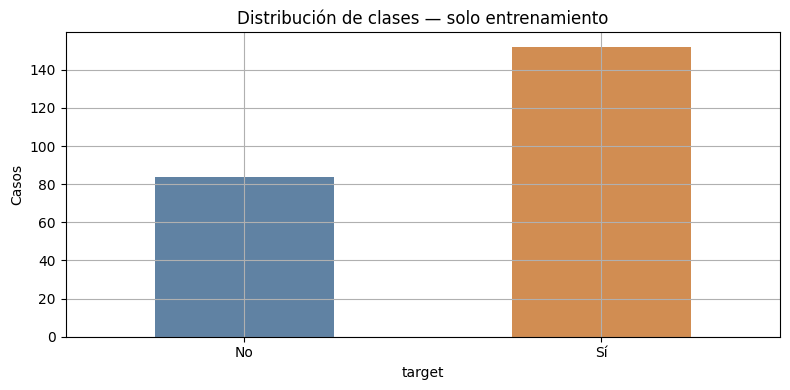

In [5]:
class_counts = pd.DataFrame({'cantidad_train': yc_train.value_counts(),
                            'porcentaje_train': yc_train.value_counts(normalize=True)*100})
class_counts.index.name = 'lesión quirúrgica (1=sí)'
display(class_counts.sort_index())
ratio = yc_train.value_counts().max()/yc_train.value_counts().min()
print(f'Razón clase mayoritaria/minoritaria: {ratio:.2f}')
yc_train.value_counts().sort_index().rename(index={0:'No',1:'Sí'}).plot.bar(color=['#6082a3','#d18d52'])
plt.title('Distribución de clases — solo entrenamiento'); plt.ylabel('Casos'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

clf_candidates = {
 'Referencia mayoritaria': (DummyClassifier(strategy='most_frequent'), {}),
 'Regresión logística': (LogisticRegression(max_iter=3000, random_state=SEED),
    {'model__C': [0.1, 1.0, 10.0], 'model__class_weight': [None, 'balanced']}),
 'Árbol de decisión': (DecisionTreeClassifier(random_state=SEED),
    {'model__max_depth': [3, 5, None], 'model__min_samples_leaf': [2, 5],
     'model__class_weight': [None, 'balanced']}),
 'Random Forest': (RandomForestClassifier(n_estimators=120, random_state=SEED, n_jobs=1),
    {'model__max_depth': [5, None], 'model__min_samples_leaf': [2, 5],
     'model__class_weight': [None, 'balanced']})
}
clf_search, clf_rows = {}, []
clf_scoring = {'f1': make_scorer(f1_score, zero_division=0),
 'precision': make_scorer(precision_score, zero_division=0),
 'recall': make_scorer(recall_score, zero_division=0), 'accuracy': 'accuracy', 'auc': 'roc_auc'}
for name, (model, params) in clf_candidates.items():
    start = time.perf_counter()
    search = GridSearchCV(Pipeline([('prep', preprocessor(numeric_clf)), ('model', model)]),
        params, cv=folds_clf, scoring=clf_scoring, refit='f1', n_jobs=1,
        error_score='raise', return_train_score=True)
    search.fit(Xc_train, yc_train)
    clf_search[name] = search
    i = search.best_index_
    clf_rows.append({'modelo': name, 'F1_CV': search.cv_results_['mean_test_f1'][i],
        'F1_CV_std': search.cv_results_['std_test_f1'][i],
        'precision_CV': search.cv_results_['mean_test_precision'][i],
        'recall_CV': search.cv_results_['mean_test_recall'][i],
        'accuracy_CV': search.cv_results_['mean_test_accuracy'][i],
        'AUC_CV': search.cv_results_['mean_test_auc'][i],
        'F1_train_CV': search.cv_results_['mean_train_f1'][i],
        'segundos': time.perf_counter()-start, 'parametros': search.best_params_})
    pd.DataFrame(search.cv_results_).to_csv(RESULTS/f'busqueda_clf_{name.replace(" ", "_")}.csv', index=False)
clf_cv = pd.DataFrame(clf_rows).sort_values('F1_CV', ascending=False).reset_index(drop=True)
selected_clf = clf_cv[clf_cv['modelo'] != 'Referencia mayoritaria'].iloc[0]['modelo']
display(clf_cv)
print('Modelo de clasificación seleccionado por validación:', selected_clf)

balance_rows = []
for name, search in clf_search.items():
    if name == 'Referencia mayoritaria': continue
    results = pd.DataFrame(search.cv_results_)
    for weight in [None, 'balanced']:
        subset = results[results['params'].map(lambda p: p['model__class_weight'] == weight)]
        best = subset.loc[subset['mean_test_f1'].idxmax()]
        balance_rows.append({'modelo': name, 'ponderacion': str(weight),
          'F1_CV': best['mean_test_f1'], 'recall_CV': best['mean_test_recall'],
          'precision_CV': best['mean_test_precision'], 'parametros': best['params']})
balance_table = pd.DataFrame(balance_rows)
display(balance_table)

### Interpretación del balanceo y estabilidad
La siguiente síntesis se construye a partir de las ejecuciones. Compara la mejor configuración de cada condición; no aísla causalmente el efecto del peso porque otros hiperparámetros pueden variar. La desviación entre folds describe variabilidad, no un intervalo de confianza.

In [6]:
for name in clf_candidates:
    if name == 'Referencia mayoritaria': continue
    rows = balance_table[balance_table.modelo == name].set_index('ponderacion')
    delta = rows.loc['balanced','F1_CV']-rows.loc['None','F1_CV']
    display(Markdown(f'**{name}:** diferencia F1 de la mejor configuración balanceada frente a la no balanceada: **{delta:+.4f}**.'))

**Regresión logística:** diferencia F1 de la mejor configuración balanceada frente a la no balanceada: **-0.0490**.

**Árbol de decisión:** diferencia F1 de la mejor configuración balanceada frente a la no balanceada: **-0.0709**.

**Random Forest:** diferencia F1 de la mejor configuración balanceada frente a la no balanceada: **-0.0323**.

## 5. Evaluación final en prueba reservada y comparación (IE2, IE5, IE6, IE7)

Los modelos de las tablas siguientes ya están ajustados con todo el entrenamiento y sus hiperparámetros se eligieron sin prueba. Reporto todos los candidatos para transparencia, pero mantengo la familia seleccionada mediante validación. Una discrepancia con el orden de prueba indica variabilidad; no autoriza a reajustar usando ese conjunto.

In [7]:
reg_test_rows = []
for name, search in reg_search.items():
    pred = search.predict(Xr_test)
    mse = mean_squared_error(yr_test, pred)
    reg_test_rows.append({'modelo': name, 'MSE_test': mse, 'RMSE_test': np.sqrt(mse),
                         'R2_test': r2_score(yr_test, pred)})
reg_test = pd.DataFrame(reg_test_rows)
reg_summary = reg_cv.merge(reg_test, on='modelo')
display(reg_summary.drop(columns=['parametros']))

clf_test_rows = []
clf_predictions = {}
for name, search in clf_search.items():
    pred = search.predict(Xc_test)
    proba = search.predict_proba(Xc_test)[:, list(search.classes_).index(1)]
    clf_predictions[name] = (pred, proba)
    clf_test_rows.append({'modelo': name, 'accuracy_test': accuracy_score(yc_test,pred),
        'precision_test': precision_score(yc_test,pred,zero_division=0),
        'recall_test': recall_score(yc_test,pred,zero_division=0),
        'F1_test': f1_score(yc_test,pred,zero_division=0), 'AUC_test': roc_auc_score(yc_test,proba)})
clf_test = pd.DataFrame(clf_test_rows)
clf_summary = clf_cv.merge(clf_test, on='modelo')
display(clf_summary.drop(columns=['parametros']))
print('Distribución de clases en prueba (después de fijar la selección):')
display(yc_test.value_counts().sort_index())

Distribución de clases en prueba (después de fijar la selección):


,modelo,RMSE_CV,RMSE_CV_std,MSE_CV,R2_CV,RMSE_train_CV,segundos,MSE_test,RMSE_test,R2_test
0,Random Forest,18.0952,2.3809,333.1042,0.5828,12.0505,16.3051,359.5347,18.9614,0.5364
1,Ridge,20.2508,2.4508,416.1008,0.4710,16.4825,1.2009,283.9678,16.8513,0.6338
2,Referencia media,28.7958,3.5950,842.1224,-0.0574,28.6875,0.2581,783.3977,27.9892,-0.0101


,modelo,F1_CV,F1_CV_std,precision_CV,recall_CV,accuracy_CV,AUC_CV,F1_train_CV,segundos,accuracy_test,precision_test,recall_test,F1_test,AUC_test
0,Random Forest,0.8339,0.0368,0.7547,0.9378,0.7631,0.7732,0.8809,20.5226,0.7188,0.7333,0.8462,0.7857,0.7303
1,Árbol de decisión,0.8041,0.0393,0.7332,0.8953,0.7243,0.7111,0.8488,5.1094,0.6562,0.6809,0.8205,0.7442,0.6610
2,Regresión logística,0.8006,0.0377,0.7436,0.8715,0.7250,0.7601,0.8731,2.8641,0.7500,0.7674,0.8462,0.8049,0.7477
3,Referencia mayoritaria,0.7804,0.0587,0.6438,1.0000,0.6438,0.5000,0.7833,0.3736,0.6094,0.6094,1.0000,0.7573,0.5000


target
0    25
1    39
Name: count, dtype: int64

<ipython-input-8-a8570fa8fb96>:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()
<ipython-input-8-a8570fa8fb96>:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()
<ipython-input-8-a8570fa8fb96>:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


,precision,recall,f1-score,support
No quirúrgica,0.6842,0.5200,0.5909,25.0000
Quirúrgica,0.7333,0.8462,0.7857,39.0000
accuracy,0.7188,0.7188,0.7188,0.7188
macro avg,0.7088,0.6831,0.6883,64.0000
weighted avg,0.7141,0.7188,0.7096,64.0000


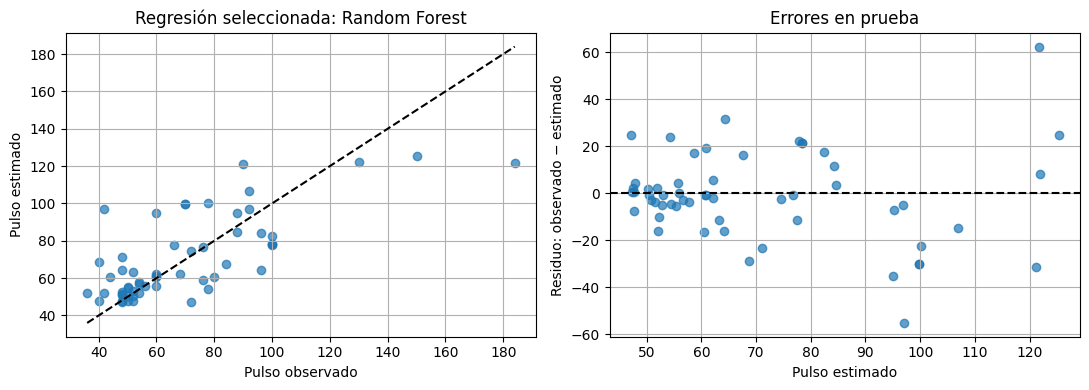

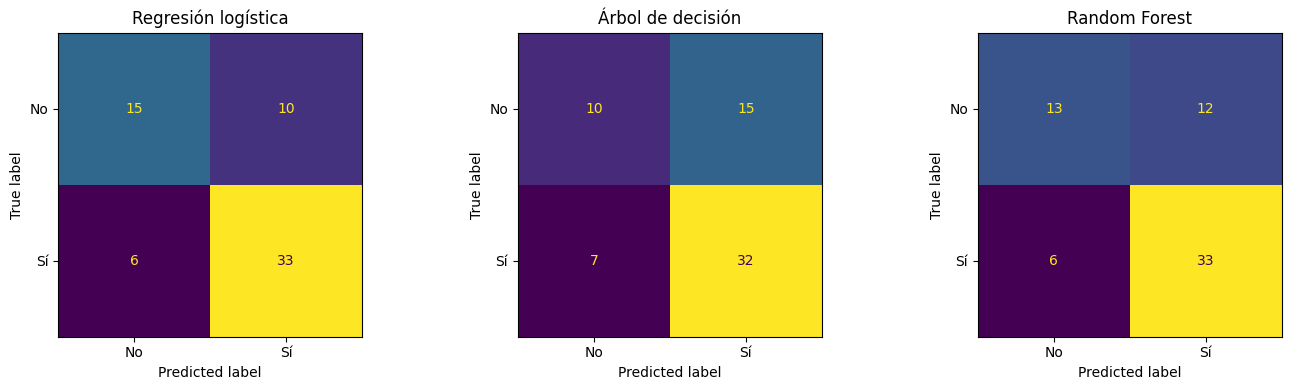

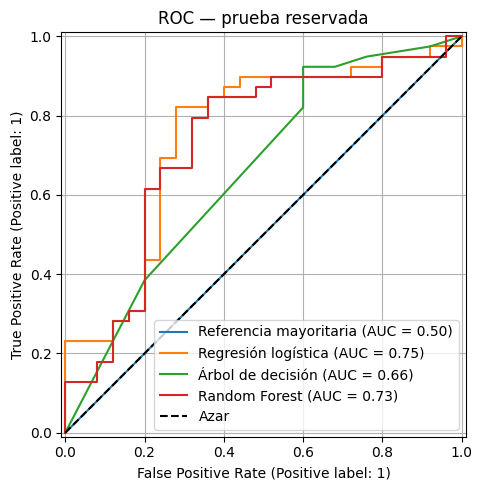

In [8]:
pred_r = reg_search[selected_reg].predict(Xr_test)
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].scatter(yr_test, pred_r, alpha=.7)
lo, hi = min(yr_test.min(),pred_r.min()), max(yr_test.max(),pred_r.max())
axes[0].plot([lo,hi],[lo,hi],'k--')
axes[0].set(xlabel='Pulso observado',ylabel='Pulso estimado',title=f'Regresión seleccionada: {selected_reg}')
axes[1].scatter(pred_r, yr_test.to_numpy()-pred_r, alpha=.7)
axes[1].axhline(0,color='black',linestyle='--')
axes[1].set(xlabel='Pulso estimado',ylabel='Residuo: observado − estimado',title='Errores en prueba')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1,3,figsize=(14,4))
for ax, name in zip(axes, [n for n in clf_search if n != 'Referencia mayoritaria']):
    pred, _ = clf_predictions[name]
    ConfusionMatrixDisplay.from_predictions(yc_test,pred,display_labels=['No','Sí'],ax=ax,colorbar=False)
    ax.set_title(name); ax.grid(False)
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(7,5))
for name, (pred, proba) in clf_predictions.items():
    RocCurveDisplay.from_predictions(yc_test,proba,name=name,ax=ax)
ax.plot([0,1],[0,1],'k--',label='Azar'); ax.set_title('ROC — prueba reservada'); ax.legend()
plt.tight_layout(); plt.show()
pred_c, proba_c = clf_predictions[selected_clf]
display(pd.DataFrame(classification_report(yc_test,pred_c,
    target_names=['No quirúrgica','Quirúrgica'],output_dict=True,zero_division=0)).T)

## 6. Selección y discusión de resultados (IE6, IE7)

Las cifras de este apartado se calculan desde las tablas anteriores. Seleccionar el mejor de los candidatos no garantiza que alcance un desempeño útil. La referencia simple puede superarlo en prueba. El conjunto es pequeño y la composición del holdout afecta a las estimaciones.

In [9]:
r = reg_summary.set_index('modelo').loc[selected_reg]
c = clf_summary.set_index('modelo').loc[selected_clf]
base_r = reg_summary.set_index('modelo').loc['Referencia media']
base_c = clf_summary.set_index('modelo').loc['Referencia mayoritaria']
tn, fp, fn, tp = confusion_matrix(yc_test,pred_c,labels=[0,1]).ravel()
display(Markdown(f"""
### Regresión
Selecciono **{selected_reg}** porque obtuvo el menor RMSE medio de validación entre las dos familias:
**{r['RMSE_CV']:.2f} ± {r['RMSE_CV_std']:.2f} pulsaciones/minuto** (media ± desviación entre folds).
En prueba obtuvo MSE **{r['MSE_test']:.2f}**, RMSE **{r['RMSE_test']:.2f}** y R² **{r['R2_test']:.3f}**.
La referencia obtuvo RMSE **{base_r['RMSE_test']:.2f}**; diferencia referencia menos seleccionado:
**{base_r['RMSE_test']-r['RMSE_test']:+.2f}** (positiva favorece al seleccionado).
La brecha de RMSE entre entrenamiento y validación es
**{r['RMSE_CV']-r['RMSE_train_CV']:.2f}**. Debe interpretarse junto con la dispersión y los residuos.

### Clasificación
Selecciono **{selected_clf}** por su F1 positivo medio de validación:
**{c['F1_CV']:.3f} ± {c['F1_CV_std']:.3f}**. En prueba obtuvo accuracy **{c['accuracy_test']:.3f}**,
precisión **{c['precision_test']:.3f}**, recall **{c['recall_test']:.3f}**, F1 **{c['F1_test']:.3f}**
y ROC/AUC **{c['AUC_test']:.3f}**. La referencia obtuvo F1 **{base_c['F1_test']:.3f}**.
La matriz incluye **{fn} falsos negativos** y **{fp} falsos positivos**, además de {tp} verdaderos positivos
y {tn} verdaderos negativos. Los falsos negativos representan lesiones quirúrgicas etiquetadas como no quirúrgicas;
los falsos positivos representan el error contrario. Son errores predictivos retrospectivos, no tratamientos observados.
La brecha de F1 entrenamiento menos validación es **{c['F1_train_CV']-c['F1_CV']:.3f}**;
una brecha amplia es compatible con sobreajuste, sin constituir por sí sola una prueba definitiva.
"""))
print('Hiperparámetros de regresión:', reg_search[selected_reg].best_params_)
print('Hiperparámetros de clasificación:', clf_search[selected_clf].best_params_)

Hiperparámetros de regresión: {'model__max_depth': 5, 'model__max_features': 0.7, 'model__min_samples_leaf': 2}
Hiperparámetros de clasificación: {'model__class_weight': None, 'model__max_depth': 5, 'model__min_samples_leaf': 5}



### Regresión
Selecciono **Random Forest** porque obtuvo el menor RMSE medio de validación entre las dos familias:
**18.10 ± 2.38 pulsaciones/minuto** (media ± desviación entre folds).
En prueba obtuvo MSE **359.53**, RMSE **18.96** y R² **0.536**.
La referencia obtuvo RMSE **27.99**; diferencia referencia menos seleccionado:
**+9.03** (positiva favorece al seleccionado).
La brecha de RMSE entre entrenamiento y validación es
**6.04**. Debe interpretarse junto con la dispersión y los residuos.

### Clasificación
Selecciono **Random Forest** por su F1 positivo medio de validación:
**0.834 ± 0.037**. En prueba obtuvo accuracy **0.719**,
precisión **0.733**, recall **0.846**, F1 **0.786**
y ROC/AUC **0.730**. La referencia obtuvo F1 **0.757**.
La matriz incluye **6 falsos negativos** y **12 falsos positivos**, además de 33 verdaderos positivos
y 13 verdaderos negativos. Los falsos negativos representan lesiones quirúrgicas etiquetadas como no quirúrgicas;
los falsos positivos representan el error contrario. Son errores predictivos retrospectivos, no tratamientos observados.
La brecha de F1 entrenamiento menos validación es **0.047**;
una brecha amplia es compatible con sobreajuste, sin constituir por sí sola una prueba definitiva.


### Lectura de resultados

La síntesis anterior se genera desde esta ejecución. Los valores del estudio original se conservan solo en la evidencia privada y no se presentan como resultados nuevos. La selección por validación se conserva aunque otro candidato obtenga mejor resultado en prueba.

### Limitaciones y mejoras justificadas

1. **Pocos casos y una sola partición externa:** los resultados pueden variar. Como trabajo posterior se puede hacer validación agrupada anidada o repetida, sin reutilizar prueba para ajustar decisiones.
2. **Variables y temporalidad:** no hay trazabilidad temporal suficiente para demostrar disponibilidad antes del diagnóstico. Los códigos de edad y la escala de proteínas requieren aclaración; no se atribuye significado a códigos no documentados.
3. **Ausencia de etiquetas de pulso:** excluir casos sin etiqueta impide comprobar el rendimiento precisamente en esos casos. No debe confundirse predicción supervisada evaluable con imputación clínicamente validada.
4. **Tratamiento de faltantes:** mediana y moda son aproximaciones. No demuestran ausencia de sesgo ni que los faltantes sean aleatorios.
5. **Selección limitada:** las rejillas no exploran todo el espacio. No se calibra probabilidad ni se optimiza un umbral clínico; `predict` utiliza la regla por defecto de cada estimador.
6. **Dependencia de EP1:** el conocimiento previo de los 300 casos influyó en exclusiones heredadas. No hay validación prospectiva; no se afirma generalización a otros centros.

### Conclusión del borrador
Implementé dos familias de regresión y tres de clasificación, además de referencias simples. Ajusté sus hiperparámetros con validación cruzada agrupada y comparé el efecto de la ponderación de clases. Las selecciones se fundamentan en criterios definidos antes de evaluar prueba; los resultados cuantitativos se presentan arriba sin sustituirlos por cifras de otros proyectos. El valor práctico de los modelos necesita validación adicional y una justificación del caso de uso por el estudiante.

**Revisión personal antes de entregar:** debo explicar con mis palabras por qué elegí ambos objetivos, interpretar los errores observados, revisar si los resultados respaldan mis hipótesis y confirmar las decisiones con el equipo/docente. No presento el texto generado como análisis independiente propio.

## 7. Trazabilidad, archivos de resultados y comprobaciones

Los CSV permiten revisar cada combinación y los folds sin repetir la búsqueda. Las tablas de prueba no se usan para cambiar la selección. El archivo de configuración registra versiones, huella de datos y parámetros. Los tiempos dependen del equipo y no son una comparación controlada de eficiencia.

In [10]:
reg_summary.to_csv(RESULTS/'resumen_regresion.csv',index=False)
clf_summary.to_csv(RESULTS/'resumen_clasificacion.csv',index=False)
balance_table.to_csv(RESULTS/'comparacion_balanceo.csv',index=False)
pd.DataFrame({'fila_original': yr_test.index, 'observado': yr_test.to_numpy(),
              'predicho': pred_r}).to_csv(RESULTS/'predicciones_regresion.csv',index=False)
pd.DataFrame({'fila_original': yc_test.index, 'observado': yc_test.to_numpy(),
              'predicho': pred_c, 'probabilidad_positiva': proba_c}).to_csv(
                  RESULTS/'predicciones_clasificacion.csv',index=False)
manifest = {'seed': SEED, 'data_sha256': data_sha256, 'versions': versions,
 'selection': {'regression': selected_reg, 'classification': selected_clf},
 'best_params': {'regression': reg_search[selected_reg].best_params_,
                 'classification': clf_search[selected_clf].best_params_},
 'features': {'regression': numeric_reg+categorical, 'classification': numeric_clf+categorical},
 'group_column': 'hospital_number', 'cv_folds': 5,
 'train_test_rows': {'regression': [len(yr_train),len(yr_test)],
                     'classification': [len(yc_train),len(yc_test)]}}
(RESULTS/'configuracion.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
assert len(reg_search) == 3 and len(clf_search) == 4
assert np.isfinite(reg_summary[['MSE_test','RMSE_test','R2_test']].to_numpy()).all()
assert np.isfinite(clf_summary[['F1_test','AUC_test']].to_numpy()).all()
assert 'pulse' not in Xr_train.columns
assert not {'surgical_lesion','outcome','surgery','lesion_1'} & set(Xc_train.columns)
print('Comprobaciones internas superadas. Resultados guardados en:', RESULTS.name)

Comprobaciones internas superadas. Resultados guardados en: resultados


## Referencias, autoría y asistencia

- Datos: McLeish, M. y Cecile (1989), Horse Colic, UCI, https://doi.org/10.24432/C58W23, CC BY 4.0. Ver data/ATRIBUCION.md.
- scikit-learn: Pipeline, validación cruzada por grupos y GridSearchCV, https://scikit-learn.org/stable/.
- Código propio declarado por Ariel Aravena. Se conservan derechos sobre el código; no sobre los datos de terceros.
- El estudio original fue preparado con asistencia de ChatGPT/Codex en generación y revisión de código y texto. Esta versión de portafolio añade ejecución reproducible, pruebas de separación y trazabilidad. No se atribuye desarrollo sin asistencia ni autorización académica no comprobada.
- No se incluyen corpus, pesos ni fuentes de los proyectos privados de Amalan.
